In [1]:
import numpy as np
import pandas as pd
import get_klines
import treatment
import anual_factor
import coef_t_stat
import momentum_reversal

In [2]:
px,vol = get_klines.find_existing_file("30m", "2017-01-01", "2026-10-01", 1000, "vol")
ret=px.pct_change()

Using existing data: datasets\crypto_1000_30m_2017-01-01_2026-10-10_vol.pk
Using existing data: datasets\crypto_1000_30m_2017-01-01_2026-10-10_px.pk


In [3]:
def z_score(df):
    mu = np.nanmean(df, axis=1, keepdims=True)
    sd = np.nanstd(df, axis=1, ddof=1, keepdims=True)
    return (df - mu) / sd

In [4]:
ret_z = z_score(ret)

C:\Users\parra\AppData\Local\Temp\ipykernel_12612\3698664521.py:2: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(df, axis=1, keepdims=True)
c:\Users\parra\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1992: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


# Momentum

In [6]:
import momentum_reversal_gpu

C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [12]:
momentum_reversal_gpu.main(10*24*2, ret_z, "betas_zscore")

In [7]:
g = momentum_reversal_gpu.load_wide("gamma","betas_zscore")                  # time x k

In [8]:
gamma_k = g.mean(axis=0)
gamma_mean = gamma_k/gamma_k.abs().sum()

In [25]:
gamma_mean.to_csv("gamma_mean_z_score.csv")

In [39]:
gamma_mean

1     -0.202973
2     -0.040828
3     -0.033537
4     -0.015379
5     -0.013458
         ...   
476    0.002131
477    0.000891
478    0.002808
479    0.001478
480    0.004874
Length: 480, dtype: float32

In [14]:
gamma_mean = pd.read_csv("gamma_mean_z_score.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'gamma_mean_z_score.csv'

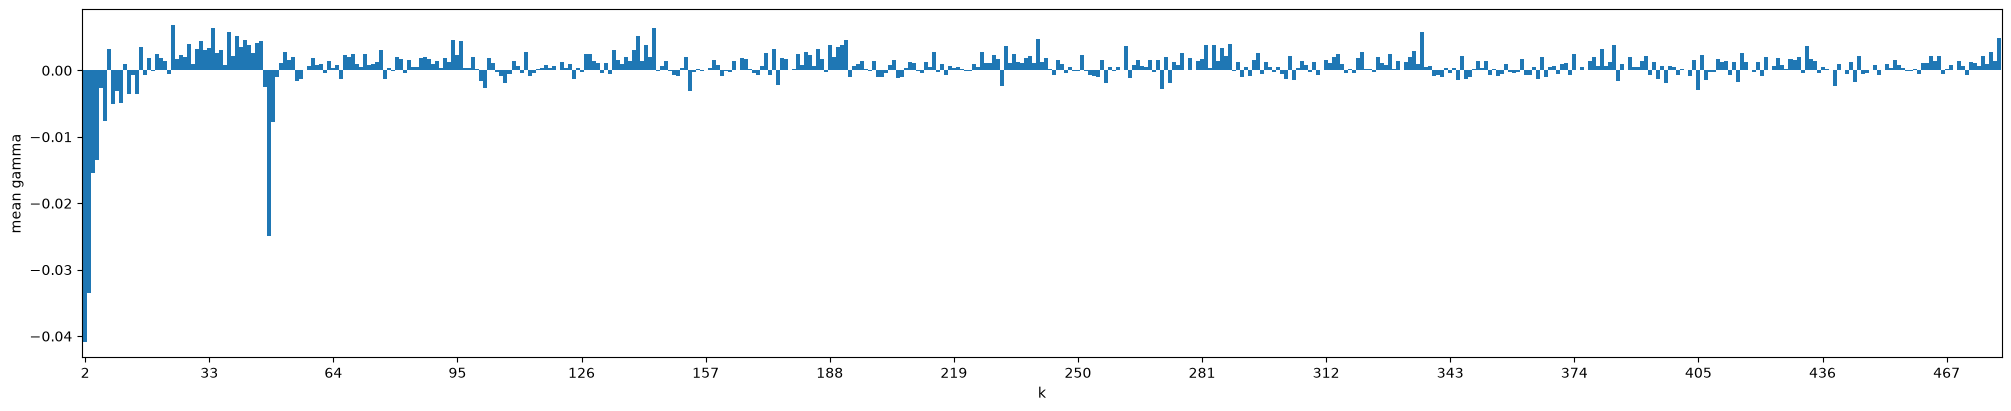

In [9]:
import matplotlib.pyplot as plt

s = gamma_mean[1:]       # iloc makes the slice explicitly positional

fig, ax = plt.subplots(figsize=(min(max(6, len(s) * 0.1), 20), 4),
                       layout="constrained")
s.plot.bar(ax=ax, width=1.0, xlabel="k", ylabel="mean gamma")

step = max(1, len(s) // 15)        # about 15 labels, whatever the length
ax.set_xticks(range(0, len(s), step))
ax.set_xticklabels(s.index[::step], rotation=0)
plt.show()

In [11]:
z = ret_z.clip(ret_z.quantile(.01, axis=1), ret_z.quantile(.99, axis=1), axis=0)
z = z.sub(z.mean(axis=1), axis=0).div(z.std(axis=1), axis=0)

# Factors

In [12]:
rev = sum(gamma_mean[k] * z.shift(k) for k in range(1, 467) if gamma_mean[k] < 0)    # lags 1-15
mom = sum(gamma_mean[k] * z.shift(k) for k in range(16, 467) if gamma_mean[k] > 0)   # lags 16-46

In [13]:
size = np.log(vol.rolling(4).mean()).shift(1)

C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\pandas\core\internals\blocks.py:354: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


In [15]:
rev.to_pickle("rev.pkl")
mom.to_pickle("mom.pkl")
size.to_pickle("size.pkl")

# Strategy

In [42]:
import q_quantile_factor_gpu

In [43]:
factors = {"rev": rev, "mom": mom, "size": size}
coefs = q_quantile_factor_gpu.factor_regression(ret, factors)

In [39]:
results=coef_t_stat.t_stat(coefs)
results

,mean,t_mean,rho,t_rho,R2,n
const,-0.000033,-2.113922,-0.021446,-0.607186,0.000460,131478.0
rev,0.000697,77.861948,-0.087808,-3.249902,0.007710,131478.0
mom,0.000048,10.338986,0.052949,8.560713,0.002804,131478.0
size,-0.000036,-13.673063,0.075625,10.964531,0.005719,131478.0


In [28]:
import multi_linear_strat

In [29]:
factors_z = {"rev": z_score(rev), "mom": z_score(mom), "size": -z_score(size)}

C:\Users\parra\AppData\Local\Temp\ipykernel_10224\3698664521.py:2: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(df, axis=1, keepdims=True)
C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\parra\AppData\Local\Temp\ipykernel_10224\3698664521.py:2: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(df, axis=1, keepdims=True)
C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_nanfunctions_impl.py:1845: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)
C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [30]:
net,bt = multi_linear_strat.main(ret, factors_z)

This is the new update


<Axes: title={'center': 'Cumulative Net Value'}, xlabel='open_time'>

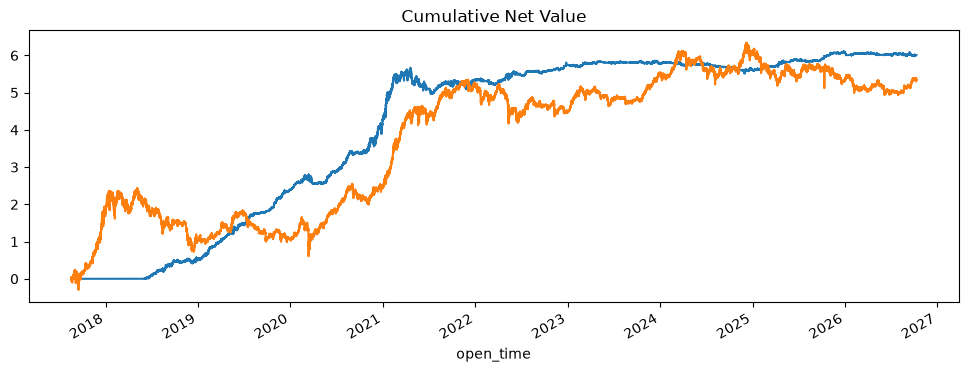

In [34]:
net.cumsum().plot(figsize=(12, 4), title="Cumulative Net Value")
ret.mean(axis=1).cumsum().plot()

In [32]:
multi_linear_strat.summarize(bt)

{'gross_ann': np.float64(0.6574903725071456),
 'gross_sharpe': np.float64(1.6940626382234996),
 'turnover/bar': np.float64(0.06795574571127247),
 'breakeven_bp': np.float64(5.522415934893925)}

# Kalman Filter

In [9]:
factors = {"rev": rev, "mom": mom, "size": size}

## Observation matrix

In [14]:
rev

,BTCUSDT,USDCUSDT,ETHUSDT,SOLUSDT,BNBUSDT,ZECUSDT,PEPEUSDT,NEARUSDT,XRPUSDT,TRXUSDT,...,USDSOLDUSDT,BTTUSDT,USDSBUSDT,HCUSDT,BCHSVUSDT,ERDUSDT,VENUSDT,STORMUSDT,PAXUSDT,BCHABCUSDT
open_time,,,,,,,,,,,,,,,,,,,,,
2017-08-17 04:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 04:30:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 05:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 05:30:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-17 06:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-09 22:00:00+00:00,0.121949,0.116906,0.093308,0.171099,0.085776,-0.008182,0.012500,-0.632107,0.076973,0.141227,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-09 22:30:00+00:00,-0.003868,-0.001386,-0.036532,-0.021821,0.110258,0.196277,0.054243,-0.174313,-0.049238,-0.024077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-09 23:00:00+00:00,0.110898,0.166994,0.108919,0.121360,0.044434,0.108705,0.032691,-0.697649,0.074837,0.196730,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
import cupy as cp
import numpy as np
import pandas as pd

CH, MIN_OBS = 20000, 30
sigs  = {"rev": rev, "mom": mom, "size": size}
names = list(sigs)
K     = len(names) + 1

ret_n = ret.to_numpy(np.float32)
sig_n = [sigs[n].reindex_like(ret).to_numpy(np.float32) for n in names]   # same index/columns as ret
T, N  = ret_n.shape

#lam_out = np.full((T, K), np.nan)
#V_out   = np.full((T, K, K), np.nan)
cy = np.full((T, K), np.nan)

for s in range(0, T, CH):
    e = min(s + CH, T)
    y = cp.asarray(ret_n[s:e], dtype=cp.float64)                              # (c, N)
    # y = gpu_clip(y, 0.01)   # optional: winsorize returns as in your factor_regression
    X = cp.stack([cp.asarray(g[s:e], dtype=cp.float64) for g in sig_n], axis=2)   # (c, N, F)

    m = cp.isfinite(y) & cp.isfinite(X).all(axis=2)                           # valid coins
    H = cp.concatenate([cp.ones_like(y)[:, :, None], X], axis=2)              # (c, N, K)
    H = cp.where(m[:, :, None], H, 0.0)
    y = cp.where(m, y, 0.0)

    Ht  = H.transpose(0, 2, 1)                                                # (c, K, N)
    HtH = Ht @ H                                                              # (c, K, K)
    Hty = Ht @ y[:, :, None]                                                  # (c, K, 1)

    n  = m.sum(axis=1)
    ok = n >= MIN_OBS                                                         # enough observations for regression
    HtH = cp.where(ok[:, None, None], HtH, cp.eye(K))                         # avoids singular matrices

    HTH_inv = cp.linalg.inv(HtH)                                              # (c, K, K)
    cy[s:e] = cp.asnumpy(cp.where(ok[:, None], (HTH_inv @ Hty)[:,:,0], cp.nan))                      # (c, K, 1)

    #lam_out[s:e] = cp.asnumpy(cp.where(ok[:, None], lam, cp.nan))
    #V_out[s:e]   = cp.asnumpy(cp.where(ok[:, None, None], V, cp.nan))
    del y, X, H, Ht, HtH, Hty
    cp.get_default_memory_pool().free_all_blocks()

In [24]:
cy = pd.DataFrame(cy, index=ret.index, columns=["intercept"] + names)

In [26]:
cy.to_pickle("cy.pkl")

In [4]:
cy = pd.read_pickle("cy.pkl")

In [5]:
cy=cy.dropna()

In [50]:
from numba import njit
import time

@njit(cache=True, nogil=True)
def _kalman_core(y, x_0, P_0, Q, R, F, H):
    T,K = y.shape
    x_prior = np.zeros((T,K)) #T x K
    P_prior = np.zeros((T,K,K)) #T x K x K
    x_prior[0] = F @ x_0
    P_prior[0] = F @ P_0 @ F.T + Q 

    error = np.zeros((T, K))
    S = np.zeros((T, K, K))
    K_gain = np.zeros((T, K, K))
    x_update = np.zeros((T, K))
    P_update = np.zeros((T, K, K))

    const = K * np.log(2 * np.pi)
    loglik = 0.0

    for t in range(T):
        error[t] = y[t] - H[t] @ x_prior[t] #T x K
        S[t] = H[t] @ P_prior[t] @ H[t].T + R[t] #T x K x K
        S_inv = np.linalg.inv(S[t])
        sign, logdet = np.linalg.slogdet(S[t])

        K_gain[t] = P_prior[t] @ H[t].T @ S_inv #T x K x K
        x_update[t] = x_prior[t] + K_gain[t] @ error[t] #T x K
        P_update[t] = (np.eye(K) - K_gain[t] @ H[t]) @ P_prior[t] #T x K x K
        if t<T-1:
            x_prior[t+1] = F @ x_update[t] #T x K 
            P_prior[t+1] = F @ P_update[t] @ F.T + Q #T x K x K
        loglik += -0.5 * (logdet + error[t].T @ S_inv @ error[t] + const)
        
    return x_update, P_update, error, S, K_gain, loglik
        

In [51]:
def kalman_filter(y, Q=None, R=None, verbose=False):
    start_time = time.time()
    T, K = np.shape(y)
    y_values = np.ascontiguousarray(y.values if isinstance(y, pd.DataFrame) else y, dtype=np.float64)

    x_0, P_0, Q, R, F, H = initial_conditions(T, K, Q, R)
    x_update, P_update, error, S, K_gain, loglik = _kalman_core(
        y_values,
        np.asarray(x_0, dtype=np.float64),
        np.ascontiguousarray(P_0, dtype=np.float64),
        np.ascontiguousarray(Q, dtype=np.float64),
        np.ascontiguousarray(R, dtype=np.float64),
        np.ascontiguousarray(F, dtype=np.float64),
        np.ascontiguousarray(H, dtype=np.float64),
    )
    if verbose:
        print(f"Kalman filter completed in {time.time()-start_time:.2f} s | loglik = {loglik:.2f}")

    x_update = pd.DataFrame(x_update, index=getattr(y, "index", None), columns=getattr(y, "columns", None))
    return x_update, P_update, error, S, K_gain, loglik

In [52]:
def initial_conditions(T,K,Q=None, R=None):
    x_0 = np.zeros(K)
    P_0 = np.eye(K)
    Q = np.eye(K) if Q is None else Q
    R = np.array([np.eye(K) for _ in range(T)]) if R is None else R
    F = np.eye(K)
    H = np.array([np.eye(K) for _ in range(T)])

    return x_0, P_0, Q, R, F, H

In [53]:
def unpack_cov(theta, K):
    L = np.zeros((K, K))
    L[np.tril_indices(K)] = theta
    d = np.diag_indices(K)
    L[d] = np.exp(L[d])
    return L @ L.T

def build_QR(theta, T, K):
    n = K * (K + 1) // 2
    Q = unpack_cov(theta[:n], K)
    R = unpack_cov(theta[n:2*n], K)
    R_t = np.array([R for _ in range(T)])    # constant R repeated -> T x K x K
    return Q, R_t

In [58]:
def neg_loglik(theta, y_arr):
    Q, R = build_QR(theta, y_arr.shape[0], y_arr.shape[1])
    ll = kalman_filter(y_arr, Q=Q, R=R)[-1]
    return 1e10 if not np.isfinite(ll) else -ll/ len(y_arr)

In [59]:
import os, time
import numpy as np

def estimate_optimizer_time(fun, theta0, args=(), maxiter=500, n_test=5, n_workers=1):
    fun(theta0, *args)                         # warm-up: numba compiles here, not timed

    t0 = time.perf_counter()
    for _ in range(n_test):
        fun(theta0, *args)
    t_eval = (time.perf_counter() - t0) / n_test

    evals_per_iter = len(theta0) + 1           # finite-difference gradient
    t_iter = t_eval * np.ceil(evals_per_iter / n_workers)

    print(f"time per likelihood evaluation: {t_eval:.4f} s")
    print(f"time per iteration:             {t_iter:.2f} s")
    print(f"expected time (upper bound, {maxiter} iterations): {t_iter * maxiter / 60:.1f} min")
    return t_eval

In [60]:
class ProgressCallback:
    def __init__(self, maxiter):
        self.start = time.time()
        self.maxiter = maxiter
        self.iter = 0

    def __call__(self, xk):
        self.iter += 1
        elapsed = time.time() - self.start
        remaining = (self.maxiter - self.iter) * elapsed / self.iter
        print(f"iteration {self.iter}/{self.maxiter} | elapsed: {elapsed:.1f} s | "
              f"max expected time to finish: {remaining:.1f} s")

In [62]:
from scipy.optimize import minimize
from multiprocessing.pool import ThreadPool
import scipy

# Prepare data
cy_arr = np.ascontiguousarray(cy.values, dtype=np.float64)
T, K = cy_arr.shape
n = K * (K + 1) // 2

theta0 = np.zeros(2 * n)

# Number of parallel workers
n_workers = 4

print("SciPy version:", scipy.__version__)
print("Workers:", n_workers)

# Warm-up (Numba compilation)
neg_loglik(theta0, cy_arr)

# Estimate runtime with parallel workers
estimate_optimizer_time(neg_loglik,theta0,args=(cy_arr,),maxiter=500,n_workers=n_workers)

# Parallel optimization
# Requires SciPy >= 1.16.0
with ThreadPool(processes=n_workers) as pool:
    res = minimize(neg_loglik,theta0,args=(cy_arr,),method="L-BFGS-B",options={"maxiter": 500,"workers": pool.map},callback=ProgressCallback(500))

# Recover estimated covariance matrices
Q_hat, R_hat = build_QR(res.x, T, K)

print("converged:", res.success, "| log-likelihood:", -res.fun)

# Final Kalman filter
x_update, P_update, error, S, K_gain, ll = kalman_filter(cy, Q=Q_hat, R=R_hat, verbose=True)

print("converged:", res.success, "| log-likelihood:", ll)

SciPy version: 1.18.1
Workers: 4
time per likelihood evaluation: 1.6038 s
time per iteration:             9.62 s
expected time (upper bound, 500 iterations): 80.2 min
iteration 1/500 | elapsed: 80.6 s | max expected time to finish: 40241.8 s
iteration 2/500 | elapsed: 124.8 s | max expected time to finish: 31085.5 s
iteration 3/500 | elapsed: 140.1 s | max expected time to finish: 23205.2 s
iteration 4/500 | elapsed: 238.5 s | max expected time to finish: 29571.8 s
iteration 5/500 | elapsed: 309.0 s | max expected time to finish: 30588.3 s
iteration 6/500 | elapsed: 341.7 s | max expected time to finish: 28132.7 s
iteration 7/500 | elapsed: 358.7 s | max expected time to finish: 25260.9 s
iteration 8/500 | elapsed: 389.7 s | max expected time to finish: 23965.5 s
iteration 9/500 | elapsed: 404.1 s | max expected time to finish: 22044.7 s
iteration 10/500 | elapsed: 418.2 s | max expected time to finish: 20492.1 s
iteration 11/500 | elapsed: 432.9 s | max expected time to finish: 19245.

In [104]:
error.to_pickle("error.pkl")
x_update.to_pickle("x_update.pkl")
np.save("./P_update.npy", P_update)
np.save("./S.npy", S)
np.save("./ll.npy", ll)
np.save("./K_gain.npy", K_gain)

In [65]:
error = pd.DataFrame(error, index=cy.index, columns=cy.columns)

(-0.1, 0.1)

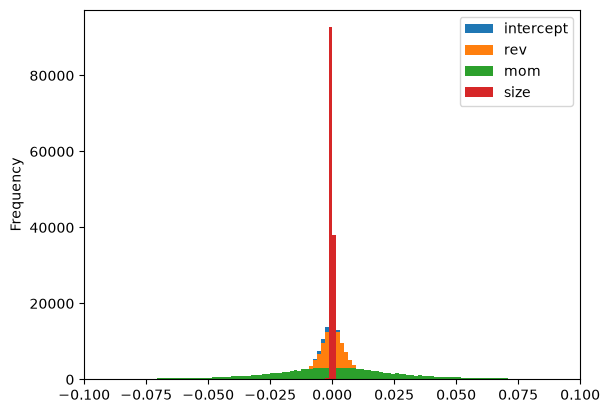

In [90]:
ax = error.plot.hist(bins=10000)
ax.set_xlim(-.1, .1)

In [92]:
# Empirical innovation covariance
S_emp = np.cov(error, rowvar=False)

# Average predicted innovation covariance
S_pred = np.mean(S, axis=0)

print("Empirical innovation covariance:")
print(S_emp)

print("\nPredicted innovation covariance:")
print(S_pred)

relative_error = (
    np.linalg.norm(S_emp - S_pred, 'fro')
    / np.linalg.norm(S_emp, 'fro')
)

print("\nRelative error:", relative_error)

Empirical innovation covariance:
[[ 1.01628753e-04  6.53718284e-07 -1.10510140e-04 -2.98936591e-06]
 [ 6.53718284e-07  2.62318582e-04  3.47434276e-04  2.15261605e-06]
 [-1.10510140e-04  3.47434276e-04  4.23036671e-03  9.51068191e-06]
 [-2.98936591e-06  2.15261605e-06  9.51068191e-06  2.15466618e-07]]

Predicted innovation covariance:
[[ 1.24596279e-04 -1.06283509e-05 -1.58373824e-04 -3.59410194e-06]
 [-1.06283509e-05  2.62477374e-04  2.81145883e-04  2.41646065e-06]
 [-1.58373824e-04  2.81145883e-04  4.35352870e-03  1.06510514e-05]
 [-3.59410194e-06  2.41646065e-06  1.06510514e-05  7.85931095e-06]]

Relative error: 0.040134856961772984


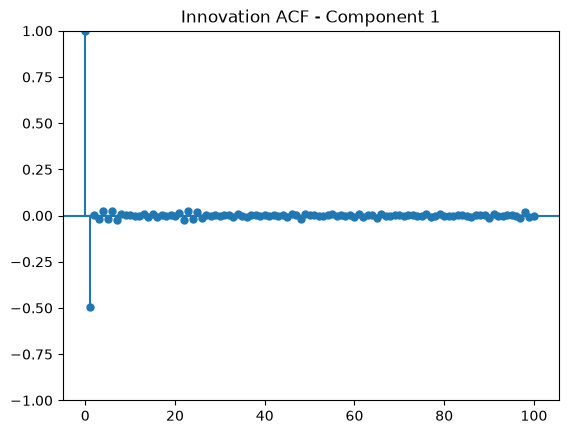

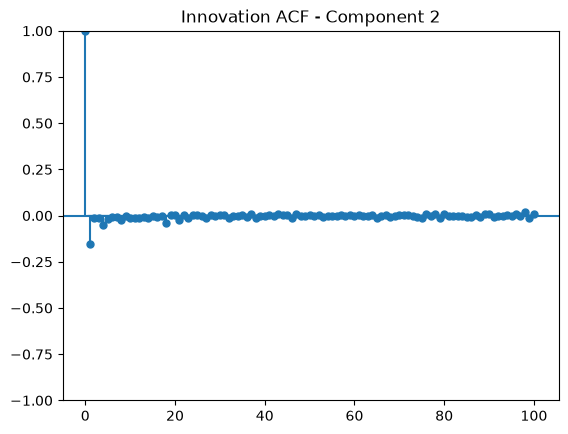

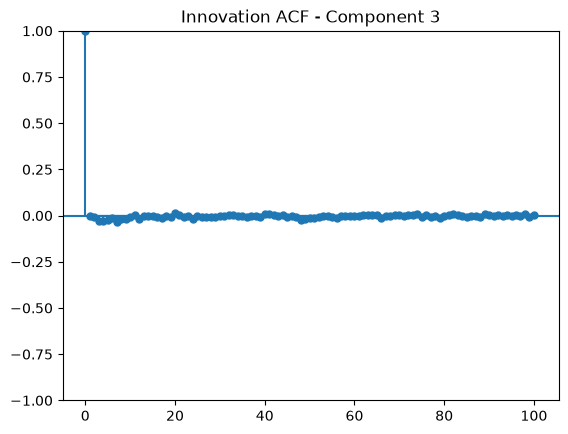

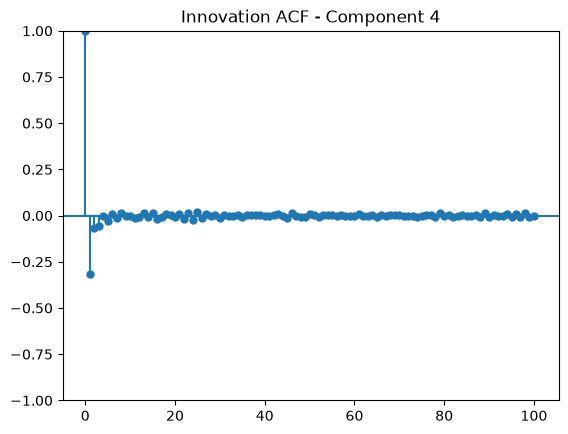

In [96]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

for i in range(4):
    plot_acf(error.iloc[:, i], lags=100)
    plt.title(f"Innovation ACF - Component {i+1}")
    plt.show()

In [ ]:
rev.to_pickle("rev.pkl")
mom.to_pickle("mom.pkl")
size.to_pickle("size.pkl")

In [ ]:

factors = {"rev": rev, "mom": mom, "size": size}

# Factor exposures known at time t
H_t = np.stack([
    np.ones(len(factors["rev"].columns)),
    factors["rev"].iloc[t].values,
    factors["mom"].iloc[t].values,
    factors["size"].iloc[t].values
], axis=1)

# One-step-ahead Kalman coefficient prediction
x_pred = F @ x_update[t]

# Expected return vector for t+1
mu_pred = H_t @ x_pred